# Modelling and Tracking Shared E-Scooters under Correlated Noise in Urban Environments

## Part I. Effects of Ignoring Correlated State and Measurement Noise in Kalman Filtering
### Background and useful recommendations

In [1]:
import numpy as np
from matplotlib import pyplot as plt

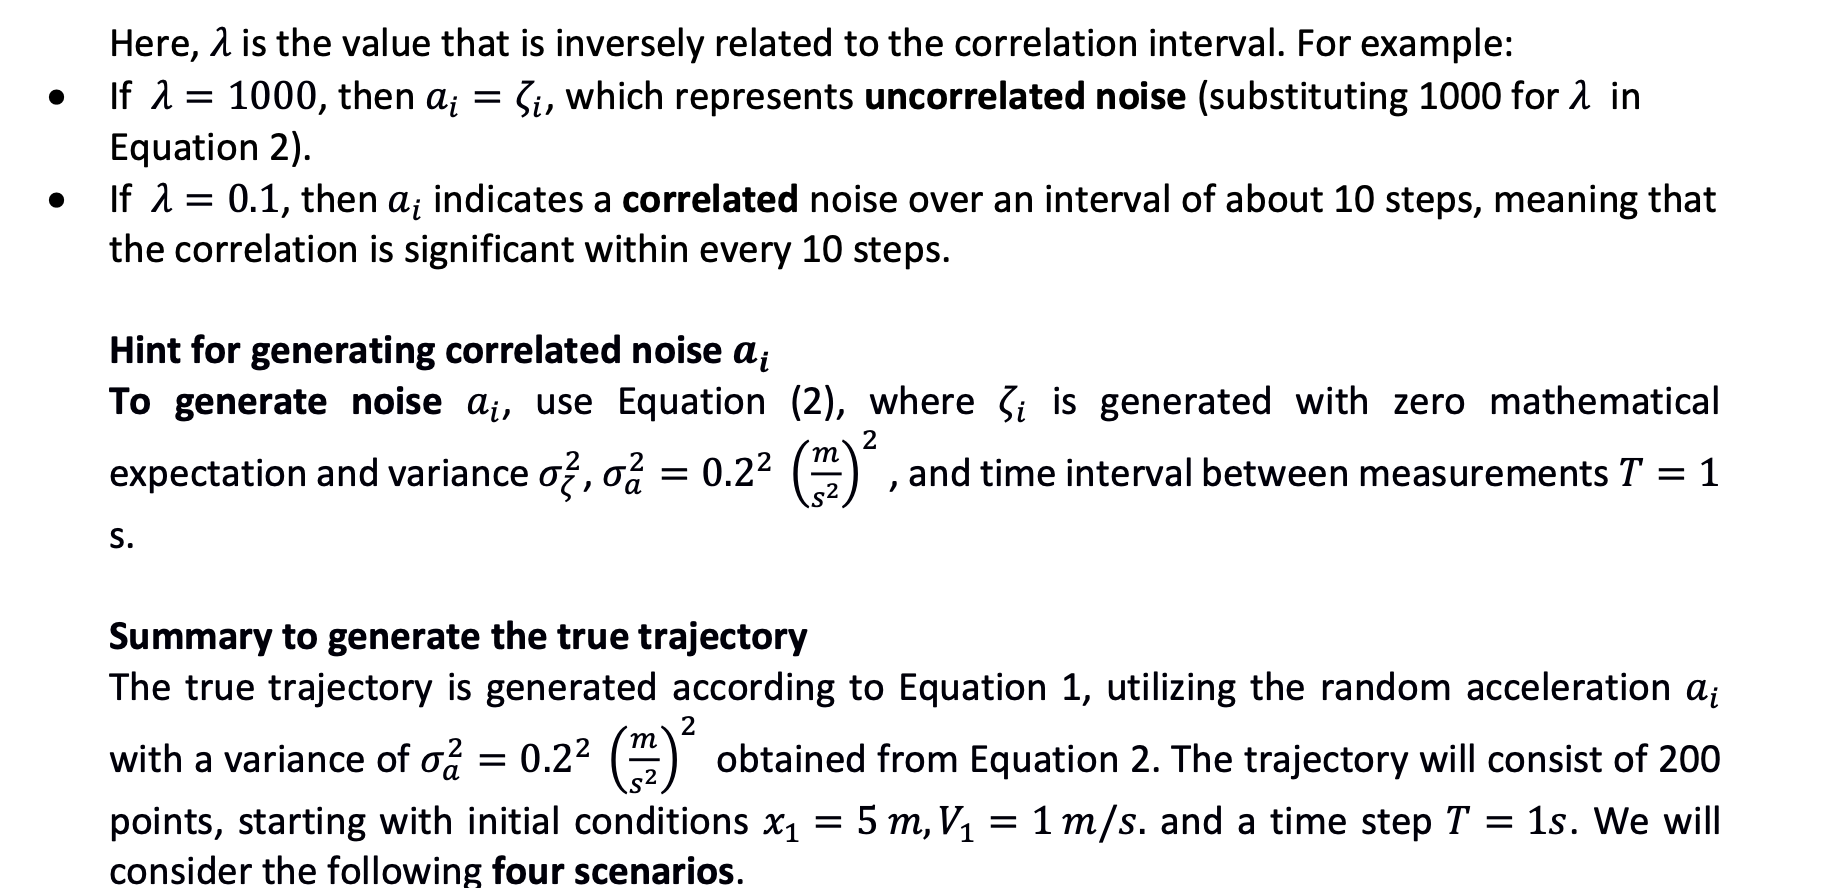

In [2]:
# defining the constants

VARIANCE_A = 0.2**2  
VARIANCE_ETA = 20**2

POINTS = 200
M = 500

T = 1
X_INIT = 5
V_INIT = 1

LAMBDA_CORRELATED = 0.1
LAMBDA_UNCORRELATED = 1000

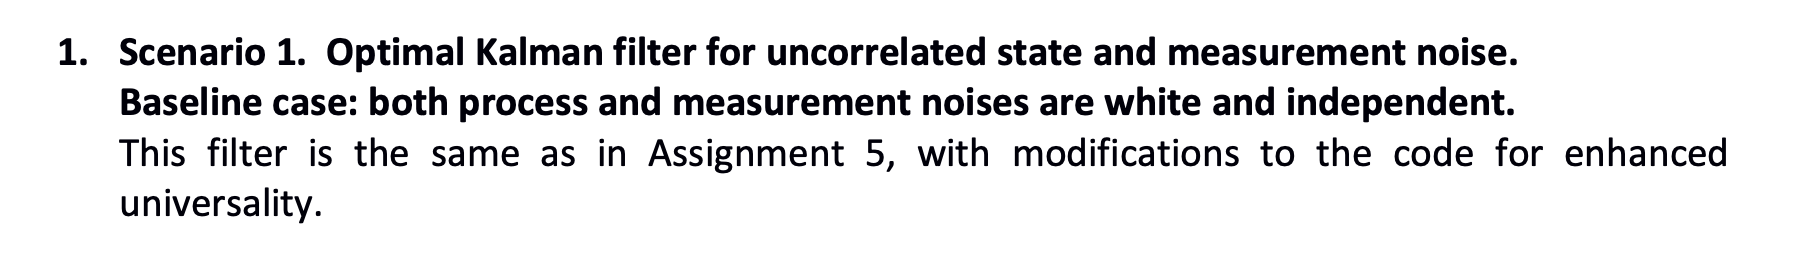

In [3]:
# state-space model for the scooter's motion

# transition matrix Phi
PHI = np.array([[1, T],
                [0, 1]])

# input matrix G that defines how the random acceleration a_i influences the state vector
G = np.array([[T**2 / 2],
              [T]])

# observation matrix H that relates the measurement vector to the state vector 
H = np.array([[1, 0]])

# covariance matrix Q of the state noise G * a_i
Q = G @ G.T * VARIANCE_A

print(Q)

# covariance matrix R of the measurement noise
R = np.array([[VARIANCE_ETA]])

print(R)

[[0.01 0.02]
 [0.02 0.04]]
[[400]]


In [4]:
# setting the initial conditions for the filtered estimate and the filtration error covariance matrix

# initial filtered estimate of the state vector 
X_0_0 = np.array([[X_INIT],
                  [V_INIT]])

# initial filtration error covariance matrix,
# identical to the more accurate matrix from assignment 6
P_0_0 = np.array([[100, 0],
                  [0, 100]])

In [5]:
# Kalman filter as a function
def kalman_filter(measurements, phi, h, q, r, x_0_0, p_0_0):
    size = measurements.size

    x_pred = np.zeros((size, 2, 1))   # predicted state X_{i,i-1}
    p_pred = np.zeros((size, 2, 2))   # prediction error covariance P_{i,i-1}
    x_filt = np.zeros((size, 2, 1))   # filtered state X_{i,i}
    p_filt = np.zeros((size, 2, 2))   # filtration error covariance P_{i,i}
    k = np.zeros((size, 2, 1))        # filter gain K_i

    identity = np.eye(2)
    x_prev = x_0_0
    p_prev = p_0_0

    for i in range(size):
        # prediction
        x_pred[i] = phi @ x_prev
        p_pred[i] = phi @ p_prev @ phi.T + q

        # filtration
        k[i] = p_pred[i] @ h.T @ np.linalg.inv(h @ p_pred[i] @ h.T + r)
        x_filt[i] = x_pred[i] + k[i] * (measurements[i] - h @ x_pred[i])
        p_filt[i] = (identity - k[i] @ h) @ p_pred[i]

        x_prev = x_filt[i]
        p_prev = p_filt[i]

    return x_pred, p_pred, x_filt, p_filt, k

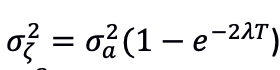

In [6]:
# find zeta
def get_zeta(lam, variance_a=VARIANCE_A, t=T):
    variance_zeta = variance_a * (1 - np.exp(-2 * lam * t))
    return np.random.normal(loc=0.0, scale=np.sqrt(variance_zeta))

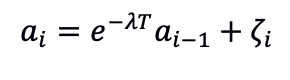
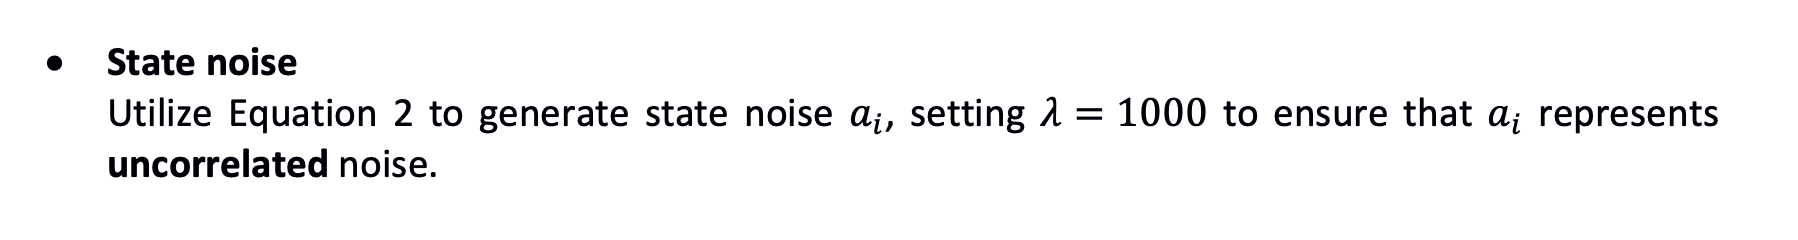

In [7]:
# a function to generate a true trajectory of an e-scooter 
def generate_true_trajectory(lam, size=POINTS, init_coord=X_INIT, init_velocity=V_INIT, sigma_a=np.sqrt(VARIANCE_A), t=T):
    traj_points = np.zeros(size)
    velocity_points = np.zeros(size)
    traj_points[0] = init_coord
    velocity_points[0] = init_velocity
    acceleration = np.random.normal(loc=0.0, scale=sigma_a)

    for i in range(1, size):
        zeta = get_zeta(lam)
        acceleration = np.exp(-lam * t) * acceleration + zeta
        traj_points[i] = traj_points[i-1] + velocity_points[i-1] * t + acceleration * t**2 / 2
        velocity_points[i] = velocity_points[i-1] + acceleration * t

    return traj_points, velocity_points

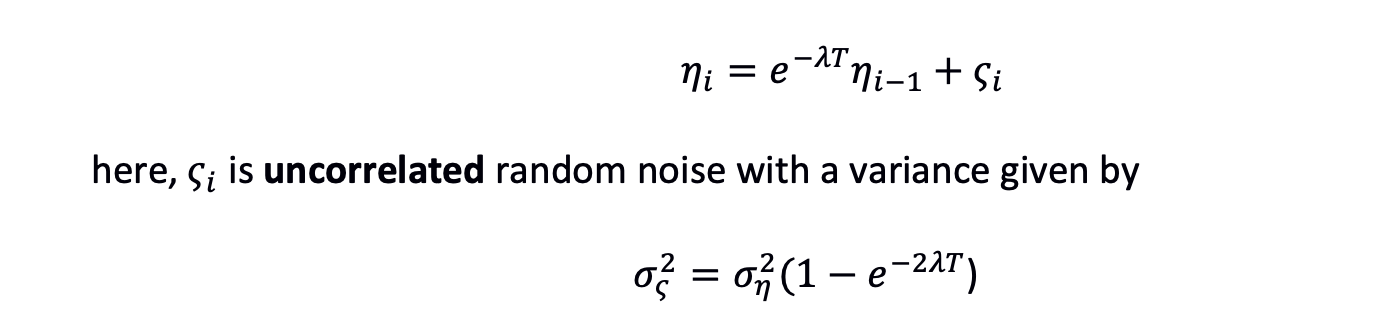

In [ ]:
# correlated noise
etas = 

# a function to generate measurements of the coordinate
def generate_measurements(true_trajectory, eta, lam, t):
    for i in range(len(true_trajectory)):
        eta = np.exp(-lam * t) * eta + 
    return measurements